# Task 3 – Bộ ảnh chuỗi chữ số viết tay: khám phá dữ liệu

Notebook này mô tả bộ dữ liệu dùng cho Task 3 (mục 3.1 của báo cáo). Mô hình nằm ở notebook `05_task3_model.ipynb`.

**Nguồn gốc dữ liệu.** Nhóm tự sinh ảnh bằng kỹ thuật *data synthesis* (chương 5.3): ghép ngẫu nhiên 3–8 ảnh chữ số đơn của MNIST (LeCun và cộng sự, 1998) thành một dãy nằm ngang. Mỗi mẫu gồm một ảnh và chuỗi chữ số tương ứng, ví dụ ảnh → `"20369"`.

- **MNIST gốc:** https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz (60.000 ảnh train, 10.000 ảnh test, 28 × 28).
- **Script sinh ảnh:** `FinalDeepData/task3/generate_data.py` (bản v1) và `generate_data_v2.py` (bản v2). Seed cố định nên chạy lại sẽ ra đúng bộ ảnh này.
- **Hai phiên bản:** v1 là bản đầu tiên của nhóm (chữ số luôn tách rời); v2 khó hơn (chữ số sát hoặc chồng nhẹ lên nhau, xoay, nghiêng, mờ, đổi độ đậm nét), giống chữ viết thật hơn. **Mô hình chính được huấn luyện trên v2.**

Notebook chạy được cả trên máy lẫn Google Colab. Trên Colab, tải `FinalDeepData_hoan_chinh.zip` lên rồi bỏ dấu `#` ở dòng `!unzip` bên dưới.

In [1]:
# !unzip -q FinalDeepData_hoan_chinh.zip      # chỉ cần trên Colab

import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

DATA_ROOT = "FinalDeepData"
sys.path.append(os.path.join(DATA_ROOT, "common"))
from data_utils import load_task3, encode_labels, decode_tokens, augment, PAD, BOS, EOS, VOCAB_SIZE

TASK3_DIR = os.path.join(DATA_ROOT, "task3", "data")
VERSIONS = {"v1": os.path.join(TASK3_DIR, "mnist_sequences_v1"),
            "v2": os.path.join(TASK3_DIR, "mnist_sequences_v2")}
SPLITS = ["train", "validation", "test"]
FIG_DIR = os.path.join("task3_outputs", "figures")
os.makedirs(FIG_DIR, exist_ok=True)

# Kiểu hình: lưới mờ, bỏ viền trên/phải; màu theo thứ tự cố định
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e"})
COLORS = {"v1": "#2a78d6", "v2": "#eb6834"}

## 1. Đọc nhãn và kích thước ảnh gốc

Mỗi phiên bản có ba file nhãn `train_labels.csv`, `validation_labels.csv`, `test_labels.csv` với ba cột `image_path`, `label`, `length`.

Nhãn **phải đọc dạng chuỗi** (`dtype={"label": str}`): nếu để pandas tự đổi sang số, nhãn `"013204"` sẽ thành `13204` và mất số 0 ở đầu. Kích thước ảnh gốc được đọc từ phần đầu file PNG (không cần giải nén cả ảnh).

In [2]:
frames = []
for version, root in VERSIONS.items():
    for split in SPLITS:
        df = pd.read_csv(os.path.join(root, f"{split}_labels.csv"), dtype={"label": str}, encoding="utf-8-sig")
        sizes = [Image.open(os.path.join(root, p)).size for p in df["image_path"]]   # (rộng, cao)
        df["width"] = [w for w, h in sizes]
        df["height"] = [h for w, h in sizes]
        df["version"], df["split"] = version, split
        frames.append(df)
meta = pd.concat(frames, ignore_index=True)

# Kiểm tra nhanh: nhãn chỉ gồm chữ số, độ dài khớp cột length
assert meta["label"].str.fullmatch(r"\d+").all()
assert (meta["label"].str.len() == meta["length"]).all()
meta.head()

,image_path,label,length,width,height,version,split
0,train/000000.png,640502,6,177,32,v1,train
1,train/000001.png,89957,5,146,32,v1,train
2,train/000002.png,035424,6,166,32,v1,train
3,train/000003.png,8671843,7,210,32,v1,train
4,train/000004.png,88269,5,152,32,v1,train


In [3]:
summary = (meta.groupby(["version", "split"], sort=False)
               .agg(so_anh=("label", "size"),
                    cao=("height", "max"),
                    rong_min=("width", "min"),
                    rong_max=("width", "max"),
                    do_dai_min=("length", "min"),
                    do_dai_max=("length", "max"),
                    ty_le_bat_dau_bang_0=("label", lambda s: s.str.startswith("0").mean()))
               .round(3))
summary

so_anh  cao  rong_min  rong_max  do_dai_min  do_dai_max  \
version split                                                                 
v1      train        20000   32        80       253           3           8   
        validation    2000   32        81       252           3           8   
        test          2000   32        81       248           3           8   
v2      train        20000   32        35       254           3           8   
        validation    2000   32        44       232           3           8   
        test          2000   32        43       237           3           8   

                    ty_le_bat_dau_bang_0  
version split                             
v1      train                      0.102  
        validation                 0.100  
        test                       0.100  
v2      train                      0.097  
        validation                 0.096  
        test                       0.104

**Nhận xét.** Mỗi phiên bản có 20.000 ảnh train, 2.000 ảnh validation và 2.000 ảnh test. Ảnh là ảnh xám (chữ trắng trên nền đen), cao 32 pixel, rộng thay đổi theo số chữ số, tối đa 256 pixel. Độ dài chuỗi từ 3 đến 8 và khoảng 10% nhãn bắt đầu bằng số 0, nên mô hình phải đọc được cả số 0 ở đầu.

## 2. Ảnh mẫu

Mỗi ảnh được đệm nền đen bên phải cho đủ 32 × 256 (xem mục 5). Bên trái là v1, bên phải là v2 (cùng chỉ số ảnh nhưng nội dung khác nhau vì hai bản sinh với seed khác nhau).

v1 train: (20000, 32, 256) uint8 | v2 train: (20000, 32, 256) uint8


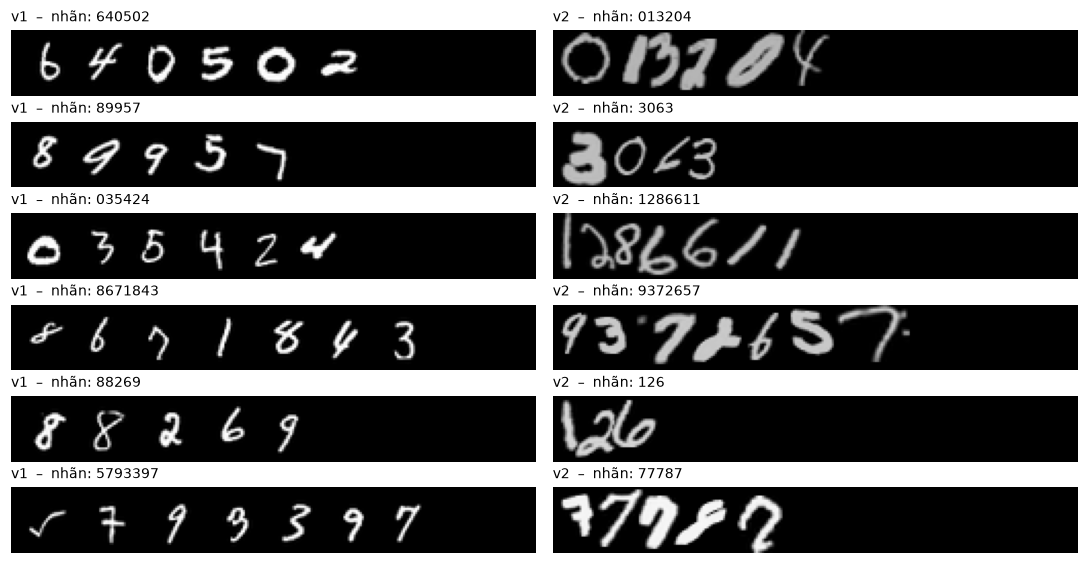

In [4]:
X1, labels1 = load_task3(VERSIONS["v1"], "train")
X2, labels2 = load_task3(VERSIONS["v2"], "train")
print("v1 train:", X1.shape, X1.dtype, "| v2 train:", X2.shape, X2.dtype)

fig, axes = plt.subplots(6, 2, figsize=(10, 5.2))
for row in range(6):
    for col, (X, labels, name) in enumerate([(X1, labels1, "v1"), (X2, labels2, "v2")]):
        ax = axes[row, col]
        ax.imshow(X[row], cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{name}  –  nhãn: {labels[row]}", fontsize=9, loc="left")
        ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "data_samples.png"), bbox_inches="tight")
plt.show()

## 3. Phân bố độ dài chuỗi và tần suất chữ số

Độ dài chuỗi được chọn đều trong khoảng 3–8 và mỗi chữ số 0–9 được chọn đều, nên không có lớp nào bị lệch (chương 5.3 nêu mất cân bằng lớp là một nguyên nhân làm mô hình dự đoán kém).

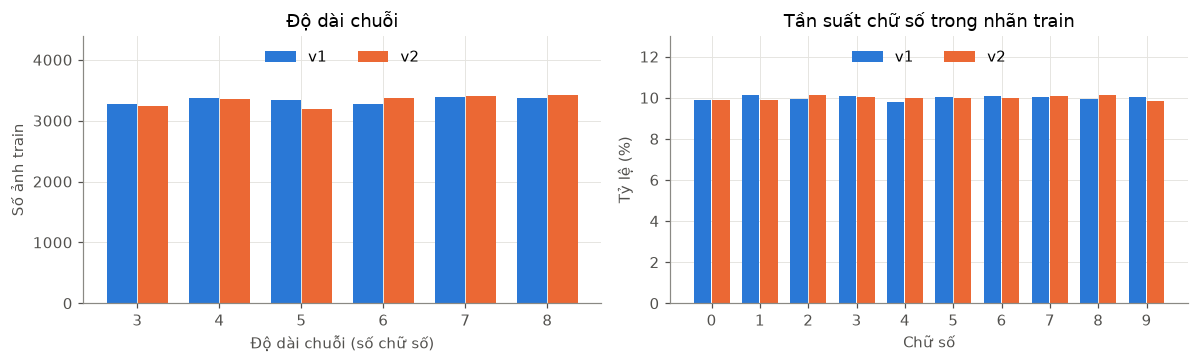

In [5]:
train_meta = meta[meta["split"] == "train"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))

lengths = np.arange(3, 9)
for i, version in enumerate(["v1", "v2"]):
    counts = train_meta[train_meta["version"] == version]["length"].value_counts().reindex(lengths)
    axes[0].bar(lengths + (i - 0.5) * 0.38, counts.values, width=0.36, color=COLORS[version], label=version)
axes[0].set(xlabel="Độ dài chuỗi (số chữ số)", ylabel="Số ảnh train", title="Độ dài chuỗi",
            ylim=(0, axes[0].get_ylim()[1] * 1.22))
axes[0].legend(frameon=False, ncol=2, loc="upper center")

for i, version in enumerate(["v1", "v2"]):
    digits = "".join(train_meta[train_meta["version"] == version]["label"])
    freq = pd.Series(list(digits)).value_counts().reindex([str(d) for d in range(10)]) / len(digits)
    axes[1].bar(np.arange(10) + (i - 0.5) * 0.38, freq.values * 100, width=0.36, color=COLORS[version], label=version)
axes[1].set(xlabel="Chữ số", ylabel="Tỷ lệ (%)", title="Tần suất chữ số trong nhãn train", xticks=range(10),
            ylim=(0, axes[1].get_ylim()[1] * 1.22))
axes[1].legend(frameon=False, ncol=2, loc="upper center")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "data_length_digit_distribution.png"), bbox_inches="tight")
plt.show()

## 4. Bề rộng ảnh theo độ dài chuỗi

Ở v1, bề rộng ảnh gần như tách hẳn theo độ dài (trong tập train, ảnh 3 chữ số rộng 80–101 pixel, ảnh 8 chữ số rộng 213–253 pixel; xem bảng dưới hình): mô hình có thể đoán độ dài chỉ bằng cách nhìn chỗ hết nét chữ. Ở v2, các khoảng chồng lấn nhiều (3 chữ số: 35–117 pixel; 8 chữ số: 107–254 pixel) nên mô hình phải thực sự đọc từng chữ số. Đây là lý do nhóm dùng v2 làm bộ chính. Hộp trong hình bao 50% số ảnh ở giữa, râu kéo tới 1,5 lần khoảng tứ phân vị.

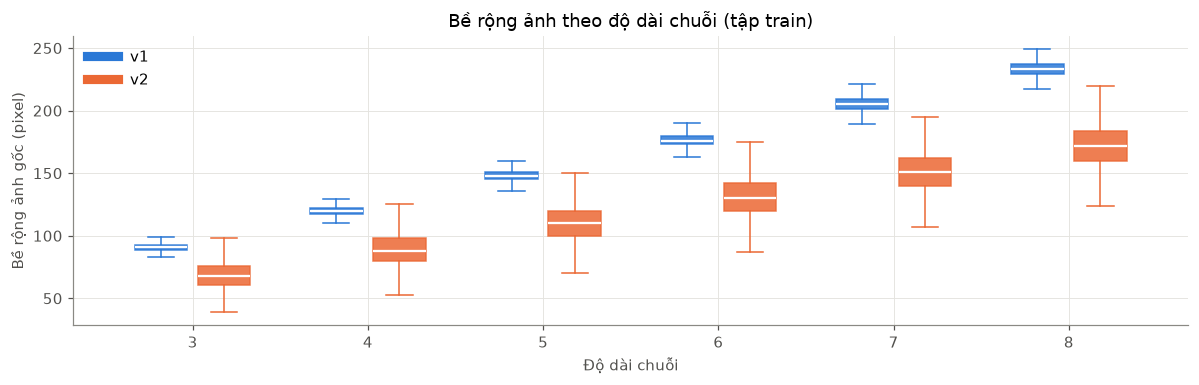

min       max     
version   v1   v2   v1   v2
length                     
3         80   35  101  117
4        106   48  133  151
5        133   66  163  170
6        159   75  193  201
7        185  101  223  221
8        213  107  253  254

In [6]:
fig, ax = plt.subplots(figsize=(11, 3.6))
for i, version in enumerate(["v1", "v2"]):
    data = [train_meta[(train_meta["version"] == version) & (train_meta["length"] == n)]["width"] for n in lengths]
    ax.boxplot(data, positions=lengths + (i - 0.5) * 0.36, widths=0.3, patch_artist=True, showfliers=False,
               boxprops=dict(facecolor=COLORS[version], edgecolor=COLORS[version], alpha=0.85),
               medianprops=dict(color="white", linewidth=1.5),
               whiskerprops=dict(color=COLORS[version]), capprops=dict(color=COLORS[version]))
    ax.plot([], [], color=COLORS[version], linewidth=6, label=version)
ax.set(xticks=lengths, xticklabels=lengths, xlabel="Độ dài chuỗi", ylabel="Bề rộng ảnh gốc (pixel)",
       title="Bề rộng ảnh theo độ dài chuỗi (tập train)")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "data_width_by_length.png"), bbox_inches="tight")
plt.show()

width_table = (train_meta.groupby(["version", "length"])["width"].agg(["min", "max"]).unstack(0))
width_table

## 5. Tiền xử lý ảnh: đệm nền đen bên phải, không kéo giãn

Mạng CNN cần ảnh cùng kích thước. Nhóm **đệm thêm nền đen bên phải** cho đủ 32 × 256 thay vì kéo giãn ảnh: kéo giãn làm chữ số béo gầy khác nhau tuỳ độ dài chuỗi (ảnh 3 chữ số bị kéo rộng gấp vài lần). Giá trị điểm ảnh được chia cho 255 để nằm trong khoảng [0, 1]. Hàm `load_task3` trong `data_utils.py` đã làm sẵn việc đệm.

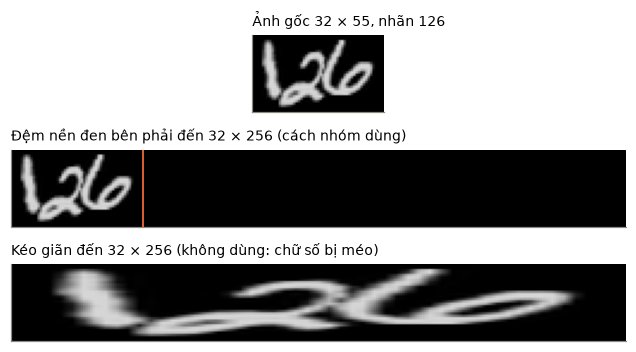

In [7]:
i = int(np.flatnonzero(train_meta[train_meta["version"] == "v2"]["length"].values == 3)[0])
row = train_meta[train_meta["version"] == "v2"].iloc[i]
original = np.asarray(Image.open(os.path.join(VERSIONS["v2"], row["image_path"])).convert("L"))
stretched = np.asarray(Image.fromarray(original).resize((256, 32), Image.Resampling.BILINEAR))

fig, axes = plt.subplots(3, 1, figsize=(8, 3.3))
axes[0].imshow(original, cmap="gray", vmin=0, vmax=255)
axes[0].set_title(f"Ảnh gốc {original.shape[0]} × {original.shape[1]}, nhãn {row['label']}", fontsize=9, loc="left")
axes[1].imshow(X2[i], cmap="gray", vmin=0, vmax=255)
axes[1].axvline(original.shape[1] - 0.5, color="#eb6834", linewidth=1.2)
axes[1].set_title("Đệm nền đen bên phải đến 32 × 256 (cách nhóm dùng)", fontsize=9, loc="left")
axes[2].imshow(stretched, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("Kéo giãn đến 32 × 256 (không dùng: chữ số bị méo)", fontsize=9, loc="left")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "data_padding.png"), bbox_inches="tight")
plt.show()

## 6. Mã hoá nhãn thành dãy token cho decoder

Decoder sinh lần lượt từng ký hiệu, giống dịch máy ở chương 8. Bộ từ vựng có 13 token: chữ số 0–9 là token 0–9, `<pad>` = 10, `<bos>` = 11 (báo bắt đầu), `<eos>` = 12 (báo kết thúc). Chuỗi dài nhất có 8 chữ số nên mỗi dãy có 8 + 1 = 9 vị trí.

- **Đầu vào decoder** (teacher forcing): `<bos>` d1 … dn, đệm `<pad>` cho đủ 9.
- **Đích cần dự đoán**: d1 … dn `<eos>`, đệm `<pad>`; vị trí `<pad>` bị bỏ qua khi tính hàm mất mát.

In [8]:
TOKEN_NAMES = [str(d) for d in range(10)] + ["<pad>", "<bos>", "<eos>"]
dec_in, dec_out = encode_labels(["20369", "013204"], max_len=8)
pd.DataFrame({"vị trí": range(1, 10),
              "đầu vào '20369'": [TOKEN_NAMES[t] for t in dec_in[0]],
              "đích '20369'": [TOKEN_NAMES[t] for t in dec_out[0]],
              "đầu vào '013204'": [TOKEN_NAMES[t] for t in dec_in[1]],
              "đích '013204'": [TOKEN_NAMES[t] for t in dec_out[1]]}).set_index("vị trí").T

vị trí,1,2,3,4,5,6,7,8,9
đầu vào '20369',<bos>,2,0,3,6,9,<pad>,<pad>,<pad>
đích '20369',2,0,3,6,9,<eos>,<pad>,<pad>,<pad>
đầu vào '013204',<bos>,0,1,3,2,0,4,<pad>,<pad>
đích '013204',0,1,3,2,0,4,<eos>,<pad>,<pad>


In [9]:
# Giải mã ngược: dừng ở <eos>, giữ nguyên số 0 ở đầu
print(decode_tokens(dec_out[0]), decode_tokens(dec_out[1]))

20369 013204


## 7. Tăng cường dữ liệu (data augmentation, chương 5.3)

Khi huấn luyện, mỗi batch được biến đổi ngẫu nhiên lại: đổi độ sáng (nhân hệ số 0,8–1,1) và thêm nhiễu Gauss. Nhãn không đổi. Nhờ vậy mô hình gần như không thấy cùng một ảnh hai lần, giảm học vẹt.

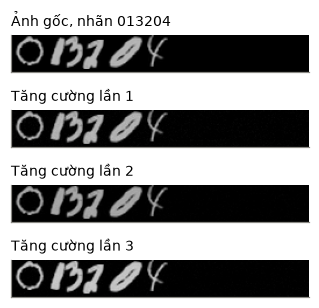

In [10]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(4, 1, figsize=(7, 2.9))
axes[0].imshow(X2[0], cmap="gray", vmin=0, vmax=255)
axes[0].set_title(f"Ảnh gốc, nhãn {labels2[0]}", fontsize=9, loc="left")
for k in range(1, 4):
    axes[k].imshow(augment(X2[:1], rng)[0], cmap="gray", vmin=0, vmax=255)
    axes[k].set_title(f"Tăng cường lần {k}", fontsize=9, loc="left")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "data_augmentation.png"), bbox_inches="tight")
plt.show()

## 8. Kiểm tra rò rỉ dữ liệu giữa các tập

Nếu cùng một nét chữ MNIST xuất hiện cả trong ảnh train lẫn ảnh test, mô hình có thể nhớ nét đó và điểm test bị thổi phồng. Vì vậy ảnh MNIST gốc được **chia trước khi ghép**: ảnh train chỉ dùng chữ số lấy từ 48.000 ảnh MNIST-train, ảnh validation dùng 12.000 ảnh MNIST-train còn lại, ảnh test dùng MNIST-test.

In [11]:
split_ids = np.load(os.path.join(VERSIONS["v1"], "source_split_indices.npz"))
train_ids, val_ids = split_ids["train_indices"], split_ids["validation_indices"]
print("Ảnh MNIST-train dùng cho train:", len(train_ids))
print("Ảnh MNIST-train dùng cho validation:", len(val_ids))
print("Số ảnh trùng giữa hai nhóm:", len(np.intersect1d(train_ids, val_ids)))
print("Tập test dùng toàn bộ", len(split_ids["test_indices"]), "ảnh MNIST-test")

Ảnh MNIST-train dùng cho train: 48000
Ảnh MNIST-train dùng cho validation: 12000
Số ảnh trùng giữa hai nhóm: 0
Tập test dùng toàn bộ 10000 ảnh MNIST-test


## 9. Tóm tắt cho mục 3.1 của báo cáo

| Mục | Nội dung |
|---|---|
| Nội dung ảnh | Dãy 3–8 chữ số viết tay (ghép từ MNIST), chữ trắng trên nền đen |
| Số ảnh | Mỗi phiên bản 24.000 ảnh: 20.000 train / 2.000 validation / 2.000 test |
| Kích thước, định dạng | PNG ảnh xám 8 bit, cao 32 pixel, rộng 35–254 pixel (v2); đệm phải thành 32 × 256 khi đưa vào mô hình |
| Nhãn | Chuỗi chữ số (giữ số 0 ở đầu), ví dụ `"013204"`; mã hoá thành 9 token với `<bos>`, `<eos>`, `<pad>` |
| Chia tập | Theo nguồn MNIST, không chữ số nào xuất hiện ở hai tập |